# Лабораторная работа №2. Задача кластеризации

**Студент:** Васютинский Вадим Александрович
**Вариант:** 8 (`lab2-08.xlsx`)

**Цель:** научиться применять модели кластеризации библиотеки scikit-learn к набору эмпирических данных.

**Результат:** число кластеров и обученная модель.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

RANDOM_STATE = 42
DATA_PATH = Path('..') / '..' / 'tasks' / 'lab2' / 'dataset' / 'lab2-08.xlsx'

## 1. Загрузка данных

In [2]:
data = pd.read_excel(DATA_PATH)
data.columns = ['x1', 'x2']
data.head()

,x1,x2
0,3.757193,-1.042462
1,1.788737,-1.772939
2,-2.608214,-1.925894
3,-1.871252,-0.173571
4,-3.728688,0.179285


In [3]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      1000 non-null   float64
 1   x2      1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB


,x1,x2
count,1000.000000,1000.000000
mean,-1.141497,-2.756044
std,4.446475,5.513910
min,-10.954978,-11.648055
25%,-4.067796,-7.252962
50%,0.250433,-2.627119
75%,2.484677,-0.963996
max,7.643615,12.613797


Файл содержит 1000 объектов с двумя числовыми признаками, пропусков нет. Оба признака измерены в одном масштабе (примерно от −12 до 13), поэтому нормализация не нужна.

## 2. Визуализация исходных данных

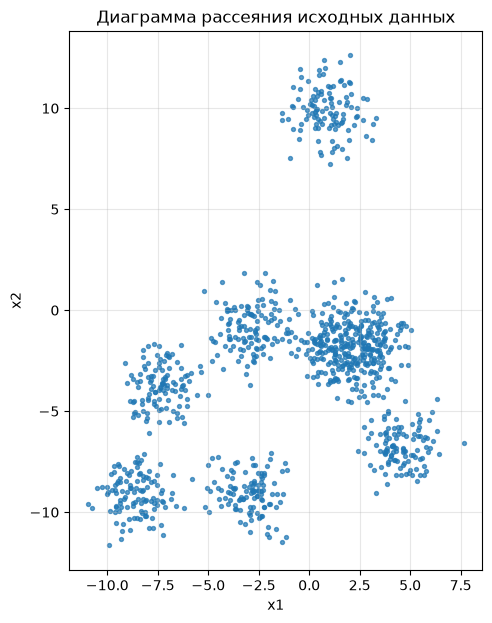

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(data['x1'], data['x2'], s=8, alpha=0.7)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Диаграмма рассеяния исходных данных')
ax.set_aspect('equal')
ax.grid(alpha=0.3)
plt.show()

На диаграмме видны компактные группы примерно круглой формы и близкого размера. Визуально групп 7; две из них (в центре, около точек (−3, −1) и (2, −2)) расположены близко и частично соприкасаются.

## 3. Оценка числа кластеров

Сначала разделим данные на обучающую (80 %) и тестовую (20 %) выборки. Число кластеров и модель
выбираются только по обучающей выборке, тестовая выборка нужна для проверки в п. 6.

In [5]:
X = data[['x1', 'x2']].to_numpy()
X_train, X_test = train_test_split(X, test_size=0.2, random_state=RANDOM_STATE)
print(f'Обучающая выборка: {len(X_train)}, тестовая: {len(X_test)}')

Обучающая выборка: 800, тестовая: 200
